/tmp/ipython-input-3367765389.py:60: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  xi[i] = prefac * np.trapz(k2Pk * j0(k * r), k)


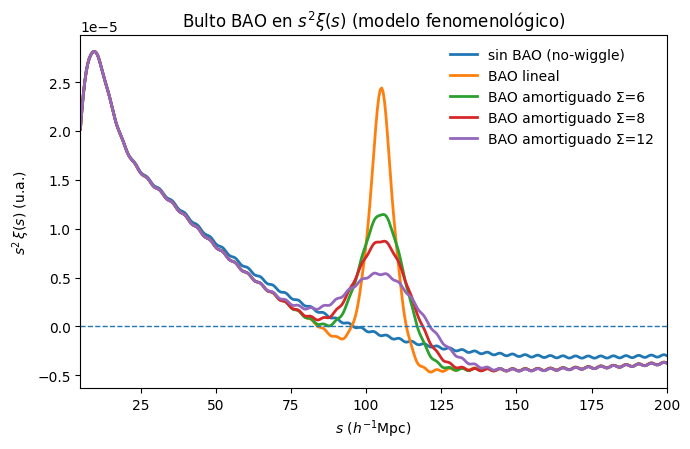

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
BAO: gráfico de s^2 xi(s) a partir de un P(k) fenomenológico con "wiggles".
No requiere SciPy; integra con trapecios y usa j0 = sin(x)/x.
"""

import numpy as np
import matplotlib.pyplot as plt

# --------- Parámetros cosmológicos/toy ----------
h = 0.7
ns = 0.965

# Coloca el bulto BAO cerca de ~105 h^-1 Mpc
r_d = 105.0  # Mpc/h

# Escalas de amortiguamiento no lineal (Mpc/h)
SIGMA_LIST = [0.0, 6.0, 8.0, 12.0]  # 0=lineal; mayor = más suavizado

# --------- P_nw(k): parte suave (sin wiggles) ----------
def P_nw(k, A=1.0, k0=0.02, alpha=2.0, beta=1.6):
    """
    Espectro 'no-wiggle' sencillo:
    - k^ns a muy grande escala
    - 'turnover' en k~k0
    - caída adicional a alta k para evitar oscilaciones por truncado
    """
    return A * (k**ns) / ((1.0 + (k/k0)**alpha) * (1.0 + (k/0.3)**(2.0*beta)))

# --------- P_bao(k): añade wiggles + amortiguamiento ----------
def P_bao(k, Sigma_nl=0.0, A_w=0.07):
    """
    P(k) = P_nw(k) * [1 + A_w sin(k r_d) exp(-k^2 Sigma_nl^2 / 2)]
    """
    damping = np.exp(-0.5 * (k * Sigma_nl)**2)
    wiggle = 1.0 + A_w * np.sin(k * r_d) * damping
    return P_nw(k) * wiggle

# --------- Bessel esférica j0 ----------
def j0(x):
    out = np.ones_like(x)
    mask = x != 0
    out[mask] = np.sin(x[mask]) / x[mask]
    return out

# --------- Transformada de Hankel: xi(r) ----------
def xi_of_r(r_vals, Pk_func, kmin=1e-4, kmax=1.5, Nk=5000):
    """
    xi(r) = (1/2π^2) ∫_0^∞ k^2 P(k) j0(k r) dk
    Integra en un grid lineal en k (suficiente para el demo).
    """
    k = np.linspace(kmin, kmax, Nk)
    Pk = Pk_func(k)
    prefac = 1.0 / (2.0 * np.pi**2)
    k2Pk = k**2 * Pk

    xi = np.empty_like(r_vals, dtype=float)
    for i, r in enumerate(r_vals):
        xi[i] = prefac * np.trapz(k2Pk * j0(k * r), k)
    return xi

def main():
    # Rango de separaciones (Mpc/h)
    s = np.linspace(5.0, 200.0, 400)

    curves = []
    labels = []

    # Curva de referencia sin BAO (no-wiggle)
    xi_nw = xi_of_r(s, lambda kk: P_nw(kk))
    curves.append(s**2 * xi_nw)
    labels.append("sin BAO (no-wiggle)")

    # Curvas con BAO para distintos Σ
    for Sigma in SIGMA_LIST:
        xi_bao = xi_of_r(s, lambda kk, S=Sigma: P_bao(kk, Sigma_nl=S))
        curves.append(s**2 * xi_bao)
        labels.append("BAO lineal" if Sigma == 0.0 else f"BAO amortiguado Σ={Sigma:.0f}")

    # ---- Gráfico ----
    plt.figure(figsize=(7.0, 4.6))
    for y, lab in zip(curves, labels):
        plt.plot(s, y, label=lab, linewidth=2.0)

    plt.xlabel(r"$s\ (h^{-1}\mathrm{Mpc})$")
    plt.ylabel(r"$s^{2}\,\xi(s)$ (u.a.)")
    plt.title(r"Bulto BAO en $s^{2}\xi(s)$ (modelo fenomenológico)")
    plt.xlim(5, 200)
    plt.axhline(0, linestyle="--", linewidth=1.0)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

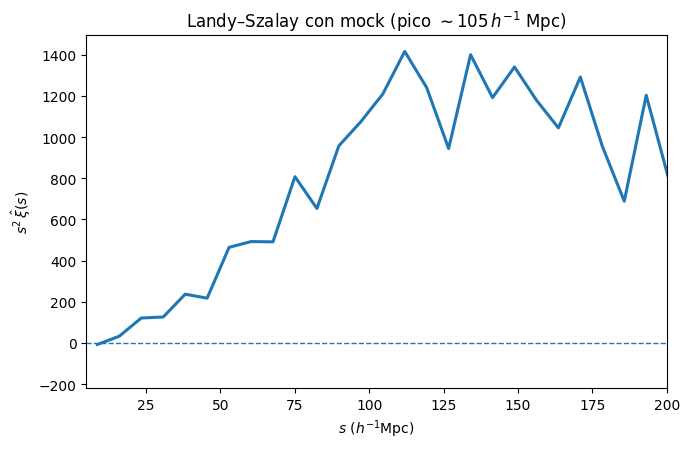

In [12]:
# --- BAO Landy–Szalay demo sin Corrfunc (Colab-ready) ---
import numpy as np
import matplotlib.pyplot as plt

def make_mock_with_bao(N_bg=1500, N_pairs=400, r_bao=105.0, box=600.0, sig=6.0, seed=7, ran_factor=3.0):
    rng = np.random.default_rng(seed)
    xyz_bg = rng.uniform(0, box, size=(N_bg, 3))
    centers = rng.uniform(0.15*box, 0.85*box, size=(N_pairs, 3))
    u = rng.normal(size=(N_pairs, 3)); u /= np.linalg.norm(u, axis=1, keepdims=True)
    r = rng.normal(loc=r_bao, scale=sig, size=N_pairs)
    disp = (r[:, None] / 2.0) * u
    a = centers - disp; b = centers + disp
    xyz_pairs = np.vstack([a % box, b % box])
    xyz_g = np.vstack([xyz_bg, xyz_pairs]).astype(float)
    w_g = np.ones(len(xyz_g), float)
    N_ran = int(max(ran_factor * len(xyz_g), 1))
    xyz_r = rng.uniform(0, box, size=(N_ran, 3)).astype(float)
    w_r = np.ones(len(xyz_r), float)
    return xyz_g, w_g, xyz_r, w_r, float(box)

def prepare_bins(smin=5.0, smax=500.0, nbins=40):
    return np.linspace(smin, smax, nbins+1)

def hist_weighted(dist_flat, w_flat, bins):
    return np.histogram(dist_flat, bins=bins, weights=w_flat)[0]

def pair_counts_auto(pos, w, bins, chunk=2000, periodic=True, boxsize=None):
    nb = len(bins) - 1
    H = np.zeros(nb, dtype=float)
    N = len(pos)
    for i0 in range(0, N, chunk):
        i1 = min(i0 + chunk, N)
        A = pos[i0:i1]; wA = w[i0:i1]
        for j0 in range(i0, N, chunk):
            j1 = min(j0 + chunk, N)
            B = pos[j0:j1]; wB = w[j0:j1]
            diff = A[:, None, :] - B[None, :, :]
            if periodic and boxsize is not None:
                diff = diff - boxsize * np.round(diff / boxsize)
            d = np.sqrt((diff * diff).sum(axis=2))
            W = (wA[:, None] * wB[None, :]).astype(float)
            if i0 == j0:
                iu = np.triu_indices(d.shape[0], k=1, m=d.shape[1])
                d = d[iu]; W = W[iu]
            else:
                d = d.ravel(); W = W.ravel()
            H += hist_weighted(d, W, bins)
    return H

def pair_counts_cross(posA, wA, posB, wB, bins, chunk=2000, periodic=True, boxsize=None):
    nb = len(bins) - 1
    H = np.zeros(nb, dtype=float)
    NA, NB = len(posA), len(posB)
    for i0 in range(0, NA, chunk):
        i1 = min(i0 + chunk, NA)
        A = posA[i0:i1]; w_a = wA[i0:i1]
        for j0 in range(0, NB, chunk):
            j1 = min(j0 + chunk, NB)
            B = posB[j0:j1]; w_b = wB[j0:j1]
            diff = A[:, None, :] - B[None, :, :]
            if periodic and boxsize is not None:
                diff = diff - boxsize * np.round(diff / boxsize)
            d = np.sqrt((diff * diff).sum(axis=2)).ravel()
            W = (w_a[:, None] * w_b[None, :]).ravel().astype(float)
            H += hist_weighted(d, W, bins)
    return H

def landy_szalay(xyz_g, w_g, xyz_r, w_r, bins, periodic=True, boxsize=None, chunk=2000):
    WG, WR = np.sum(w_g), np.sum(w_r)
    nDD = (WG**2 - np.sum(w_g**2)) / 2.0
    nRR = (WR**2 - np.sum(w_r**2)) / 2.0
    nDR = WG * WR
    DD = pair_counts_auto(xyz_g, w_g, bins, chunk, periodic, boxsize) / max(nDD, 1e-30)
    RR = pair_counts_auto(xyz_r, w_r, bins, chunk, periodic, boxsize) / max(nRR, 1e-30)
    DR = pair_counts_cross(xyz_g, w_g, xyz_r, w_r, bins, chunk, periodic, boxsize) / max(nDR, 1e-30)
    xi = (DD - 2.0*DR + RR) / np.clip(RR, 1e-30, None)
    s_centers = 0.5 * (bins[1:] + bins[:-1])
    return s_centers, xi

# --- Ejecutar demo ---
xyz_g, w_g, xyz_r, w_r, box = make_mock_with_bao(
    N_bg=1500, N_pairs=400, r_bao=105.0, box=600.0, sig=6.0, seed=7, ran_factor=3.0
)
s_edges = prepare_bins(5.0, 300.0, 40)
s, xi = landy_szalay(xyz_g, w_g, xyz_r, w_r, s_edges, periodic=True, boxsize=box, chunk=1500)

plt.figure(figsize=(7, 4.6))
plt.plot(s, s**2 * xi, lw=2.2)
plt.axhline(0, ls="--", lw=1.0)
plt.xlim(5, 200)
plt.xlabel(r"$s\ (h^{-1}\mathrm{Mpc})$")
plt.ylabel(r"$s^{2}\,\hat{\xi}(s)$")
plt.title(r"Landy–Szalay con mock (pico $\sim 105\,h^{-1}$ Mpc)")
plt.tight_layout()
plt.show()